In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
from datasets import load_dataset

In [7]:
%pip install datasets


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
emotion_dataset=load_dataset("dair-ai/emotion")

df_train_data=emotion_dataset['train']['text']
df_train_label=emotion_dataset['train']['label']

df_test_data=emotion_dataset['test']['text']
df_test_label=emotion_dataset['test']['label']

c:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Lenovo\.cache\huggingface\hub\datasets--dair-ai--emotion. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file

In [9]:
label_name=emotion_dataset['train'].features['label'].names
label_name

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [10]:
df_train=pd.DataFrame({'text':df_train_data,
                       'label': [label_name[i] for i in df_train_label]})

df_test=pd.DataFrame({'text':df_test_data,'label':[label_name[i] for i in df_test_label]})


df_train




,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [11]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words=10000

tokens=Tokenizer(num_words=max_words,oov_token='<unk>')
tokens.fit_on_texts(df_train['text'])

train_padding_sequences=pad_sequences(tokens.texts_to_sequences(df_train['text']),maxlen=50,padding='post',truncating='post')
test_padding_sequence= pad_sequences(tokens.texts_to_sequences(df_test['text']),maxlen=50,padding='post',truncating='post')

label_names_train=np.array(df_train_label)
label_names_test=np.array(df_test_label)


num_classes=len(df_train['label'].unique())
print('num_classes',num_classes)
print("Words Vocab",len(tokens.word_index))
print("max length",train_padding_sequences.shape[1])






num_classes 6
Words Vocab 15213
max length 50


In [12]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping=EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)

In [13]:
from sklearn.utils.class_weight import compute_class_weight

class_weights=compute_class_weight(class_weight='balanced',
                                classes=np.unique(label_names_train),y=label_names_train)

class_weights_dicts=dict(enumerate(class_weights))

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding,LSTM,Dense,Dropout,SimpleRNN

RNN=Sequential([
    Embedding(input_dim=max_words,output_dim=16,input_length=50),
    SimpleRNN(128,return_sequences=True),
    Dropout(0.5),
    SimpleRNN(64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])

RNN.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

RNN.fit(train_padding_sequences,label_names_train,validation_data=(test_padding_sequence,label_names_test),
          epochs=15,callbacks=[early_stopping],batch_size=32,class_weight=class_weights_dicts)


rnn_loss,rnn_accuracy=RNN.evaluate(test_padding_sequence,label_names_test)
print('rnn_accuracy',rnn_accuracy)
print('rnn_loss',rnn_loss)



c:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 39s 33ms/step - accuracy: 0.1660 - loss: 1.8419 - val_accuracy: 0.0605 - val_loss: 1.8173
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.1672 - loss: 1.7973 - val_accuracy: 0.1270 - val_loss: 1.7954
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.1610 - loss: 1.7901 - val_accuracy: 0.1090 - val_loss: 1.7869
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.1546 - loss: 1.7864 - val_accuracy: 0.1635 - val_loss: 1.7786
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - accuracy: 0.1581 - loss: 1.7758 - val_accuracy: 0.1800 - val_loss: 1.7766
Epoch 6/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - accuracy: 0.1545 - loss: 1.7770 - val_accuracy: 0.1430 - val_loss: 1.7869
Epoch 7/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - accuracy: 0.1460 - loss: 1.7671 - val_accuracy: 0.1565 - val_loss: 1.7844
Epoch 8/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - accuracy: 0.1374 - loss: 1.7671 - 

In [15]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding,LSTM,Dense,Dropout,SimpleRNN,LSTM

LSTM=Sequential([
    Embedding(input_dim=max_words,output_dim=16,input_length=50),
    LSTM(128,return_sequences=True),
    Dropout(0.5),
    LSTM(64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])

LSTM.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

LSTM.fit(train_padding_sequences,label_names_train,validation_data=(test_padding_sequence,label_names_test),
          epochs=15,callbacks=[early_stopping],batch_size=32,class_weight=class_weights_dicts)


lstm_loss,lstm_accuracy=LSTM.evaluate(test_padding_sequence,label_names_test)
print('lstm_accuracy',lstm_accuracy)
print('lstm_loss',lstm_loss)



Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 71ms/step - accuracy: 0.1446 - loss: 1.7932 - val_accuracy: 0.3475 - val_loss: 1.7796
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 34s 67ms/step - accuracy: 0.1561 - loss: 1.7930 - val_accuracy: 0.3465 - val_loss: 1.7839
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 34s 68ms/step - accuracy: 0.1803 - loss: 1.7931 - val_accuracy: 0.3470 - val_loss: 1.7878
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.3475 - loss: 1.7796
lstm_accuracy 0.3474999964237213
lstm_loss 1.7796070575714111


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding,LSTM,Dense,Dropout,SimpleRNN,LSTM,GRU

GRU=Sequential([
    Embedding(input_dim=max_words,output_dim=16,input_length=50),
    GRU(128,return_sequences=True),
    Dropout(0.5),
    GRU(64),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])

GRU.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

GRU.fit(train_padding_sequences,label_names_train,validation_data=(test_padding_sequence,label_names_test),
          epochs=15,callbacks=[early_stopping],batch_size=32,class_weight=class_weights_dicts)


gru_loss,gru_accuracy=GRU.evaluate(test_padding_sequence,label_names_test)
print('gru_accuracy',gru_accuracy)
print('gru_loss',gru_loss)



Epoch 1/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 37s 64ms/step - accuracy: 0.1564 - loss: 1.7952 - val_accuracy: 0.0330 - val_loss: 1.8079
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 31s 62ms/step - accuracy: 0.1518 - loss: 1.7949 - val_accuracy: 0.0795 - val_loss: 1.7998
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 31s 63ms/step - accuracy: 0.1353 - loss: 1.7943 - val_accuracy: 0.1375 - val_loss: 1.7754
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 31s 62ms/step - accuracy: 0.1659 - loss: 1.7939 - val_accuracy: 0.1115 - val_loss: 1.8052
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 32s 64ms/step - accuracy: 0.1629 - loss: 1.7931 - val_accuracy: 0.0825 - val_loss: 1.7804
Epoch 6/15
362/500 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.1887 - loss: 1.7947

In [ ]:
results=pd.DataFrame({'Model':['RNN','LSTM','GRU'],
                      'Accuracy':[rnn_accuracy,lstm_accuracy,gru_accuracy],
                      "loss":[rnn_loss,lstm_loss,gru_loss]}).sort_values(by='Accuracy',ascending=False)
results

,Model,Accuracy,loss
1,LSTM,0.2705,1.789076
0,RNN,0.2250,1.761842
2,GRU,0.1375,1.760374


In [ ]:
from tensorflow.keras.layers import Bidirectional
from tensorflow.keras.layers import Embedding,LSTM,Dense,Dropout,SimpleRNN,LSTM,GRU

BiGru=Sequential([
    Embedding(input_dim=max_words,output_dim=300,input_length=50),
    Bidirectional(GRU(128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])

BiGru.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


BiGru.fit(train_padding_sequences,label_names_train,validation_data=(test_padding_sequence,label_names_test),
          epochs=15,callbacks=[early_stopping],batch_size=32,class_weight=class_weights_dicts)

bigru_loss,bigru_accuracy=BiGru.evaluate(test_padding_sequence,label_names_test)
print('bigru_accuracy',bigru_accuracy)
print('bigru_loss',bigru_loss)






Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 164s 314ms/step - accuracy: 0.5595 - loss: 1.0514 - val_accuracy: 0.8880 - val_loss: 0.3204
Epoch 2/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 182s 364ms/step - accuracy: 0.9168 - loss: 0.2464 - val_accuracy: 0.9140 - val_loss: 0.2542
Epoch 3/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 177s 312ms/step - accuracy: 0.9451 - loss: 0.1582 - val_accuracy: 0.9240 - val_loss: 0.2231
Epoch 4/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 220s 350ms/step - accuracy: 0.9577 - loss: 0.1224 - val_accuracy: 0.9115 - val_loss: 0.2561
Epoch 5/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 178s 301ms/step - accuracy: 0.9631 - loss: 0.1069 - val_accuracy: 0.9150 - val_loss: 0.2659
Epoch 6/15
500/500 ━━━━━━━━━━━━━━━━━━━━ 231s 361ms/step - accuracy: 0.9724 - loss: 0.0777 - val_accuracy: 0.9250 - val_loss: 0.2363
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.9240 - loss: 0.2231
bigru_accuracy 0.9240000247955322
bigru_loss 0.22314764559268951


63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 88ms/step


<Axes: >

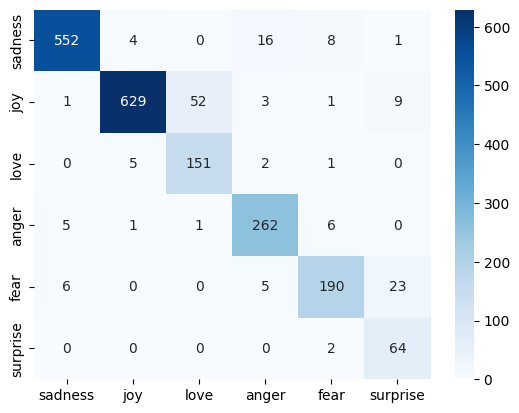

In [ ]:
from sklearn.metrics import confusion_matrix

BiGru_predictions=np.argmax(BiGru.predict(test_padding_sequence),axis=1)

sns.heatmap(confusion_matrix(label_names_test,BiGru_predictions),annot=True,fmt='d',cmap='Blues',xticklabels=label_name,yticklabels=label_name)

In [ ]:
sample_texts=[
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sequences=tokens.texts_to_sequences(sample_texts)
padded_sequences=pad_sequences(sequences,maxlen=50,padding='post',truncating='post')

sample_predictions=np.argmax(BiGru.predict(padded_sequences),axis=1)

for i in range(len(sample_texts)):
    print(f"text",{sample_texts[i]},"\nPrediction is ",{label_name[sample_predictions[i]]})

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
text {"I can't believe how happy I am right now, this is amazing!"} 
Prediction is  {'surprise'}
text {'I feel so alone and hopeless today.'} 
Prediction is  {'sadness'}
text {'I am furious that they cancelled the trip at the last minute.'} 
Prediction is  {'anger'}
text {'I feel terrified when walking down dark alleyways alone.'} 
Prediction is  {'fear'}
text {'I was shocked and completely surprised by the unexpected gift!'} 
Prediction is  {'surprise'}


In [ ]:
import os
import pickle

model_mik="Artifacts"


os.makedirs(model_mik,exist_ok=True)

BiGru.save(os.path.join(model_mik,"BiGru_model.keras"))

with open(os.path.join(model_mik,"tokenizer.pkl"),"wb") as file:
  pickle.dump(tokens,file)
  print("Model loaded successfully")




Model loaded successfully
